# EDA (Exploratory Data Analysis) of the dataset

In this notebook, explore the Abalone dataset, by showing relevant visualizations that help understand the problem you are modelling.

Please make sure to write down your conclusions in the final notebook and to remove these intructions.

# Imports

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd

pd.set_option("display.max_columns", 500)
import matplotlib.pyplot as plt
import seaborn as sns

# Data

In [ ]:
import shutil
from pathlib import Path

import kagglehub
import pandas as pd

project_root = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "pyproject.toml").is_file()
    ),
    Path.cwd(),
)
data_dir = project_root / "data"
data_dir.mkdir(parents=True, exist_ok=True)
data_path = data_dir / "abalone.csv"

if not data_path.exists():
    downloaded_dir = Path(
        kagglehub.dataset_download(
            "rodolfomendes/abalone-dataset",
            output_dir=str(data_dir),
        )
    )
    csv_files = sorted(downloaded_dir.rglob("*.csv"))
    matching_files = [path for path in csv_files if path.name.lower() == "abalone.csv"]
    if len(matching_files) == 1:
        downloaded_csv = matching_files[0]
    elif not matching_files and len(csv_files) == 1:
        downloaded_csv = csv_files[0]
    else:
        raise FileNotFoundError(
            f"Expected one Abalone CSV in {downloaded_dir}, found: {csv_files}"
        )

    if downloaded_csv.resolve() != data_path.resolve():
        shutil.copy2(downloaded_csv, data_path)

df = pd.read_csv(data_path)

# EDA

Shape: (4177, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   object 
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole weight    4177 non-null   float64
 5   Shucked weight  4177 non-null   float64
 6   Viscera weight  4177 non-null   float64
 7   Shell weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 293.8+ KB


,count,mean,std,min,25%,50%,75%,max
Length,4177.0,0.523992,0.120093,0.0750,0.4500,0.5450,0.615,0.8150
Diameter,4177.0,0.407881,0.099240,0.0550,0.3500,0.4250,0.480,0.6500
Height,4177.0,0.139516,0.041827,0.0000,0.1150,0.1400,0.165,1.1300
Whole weight,4177.0,0.828742,0.490389,0.0020,0.4415,0.7995,1.153,2.8255
Shucked weight,4177.0,0.359367,0.221963,0.0010,0.1860,0.3360,0.502,1.4880
Viscera weight,4177.0,0.180594,0.109614,0.0005,0.0935,0.1710,0.253,0.7600
Shell weight,4177.0,0.238831,0.139203,0.0015,0.1300,0.2340,0.329,1.0050
Rings,4177.0,9.933684,3.224169,1.0000,8.0000,9.0000,11.000,29.0000


,count,unique,top,freq
Sex,4177,3,M,1528


Missing values per column:
Sex               0
Length            0
Diameter          0
Height            0
Whole weight      0
Shucked weight    0
Viscera weight    0
Shell weight      0
Rings             0
dtype: int64

Duplicate rows: 0

Sex:
Sex
M    1528
I    1342
F    1307
Name: count, dtype: int64


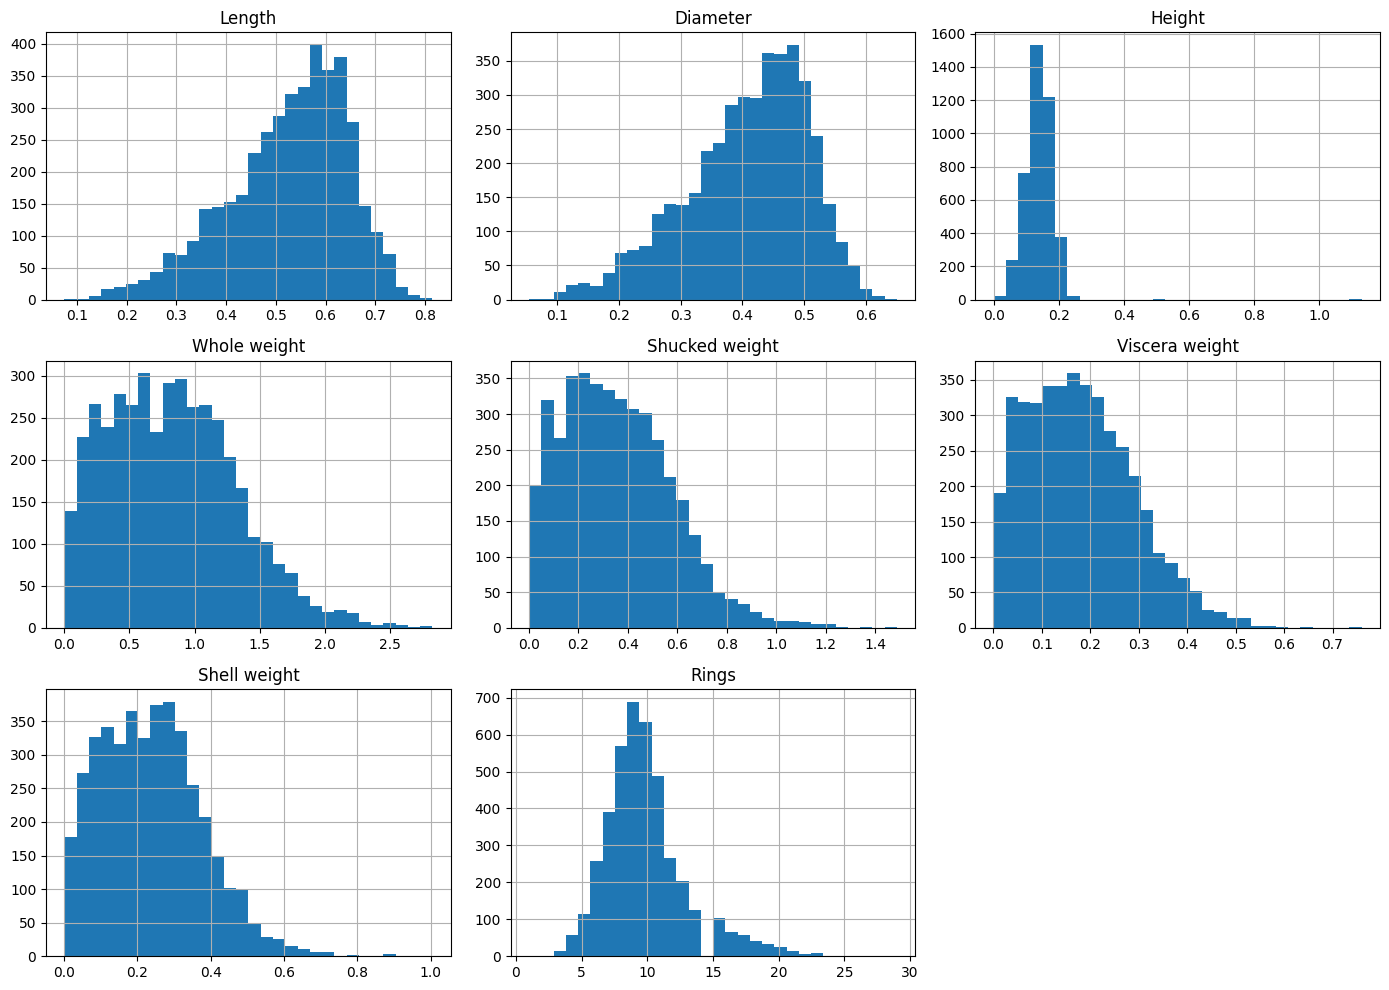

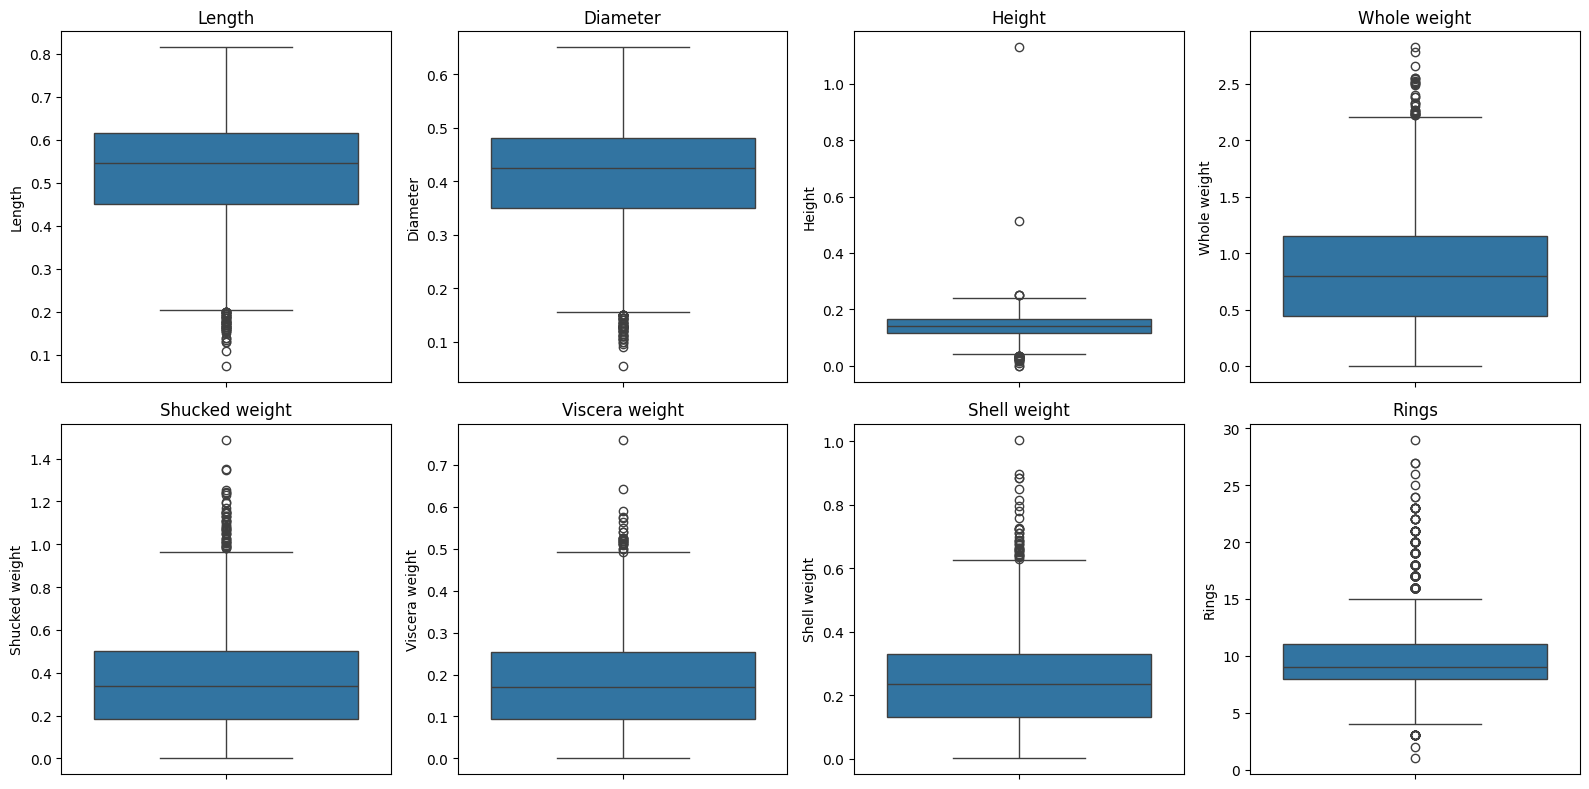

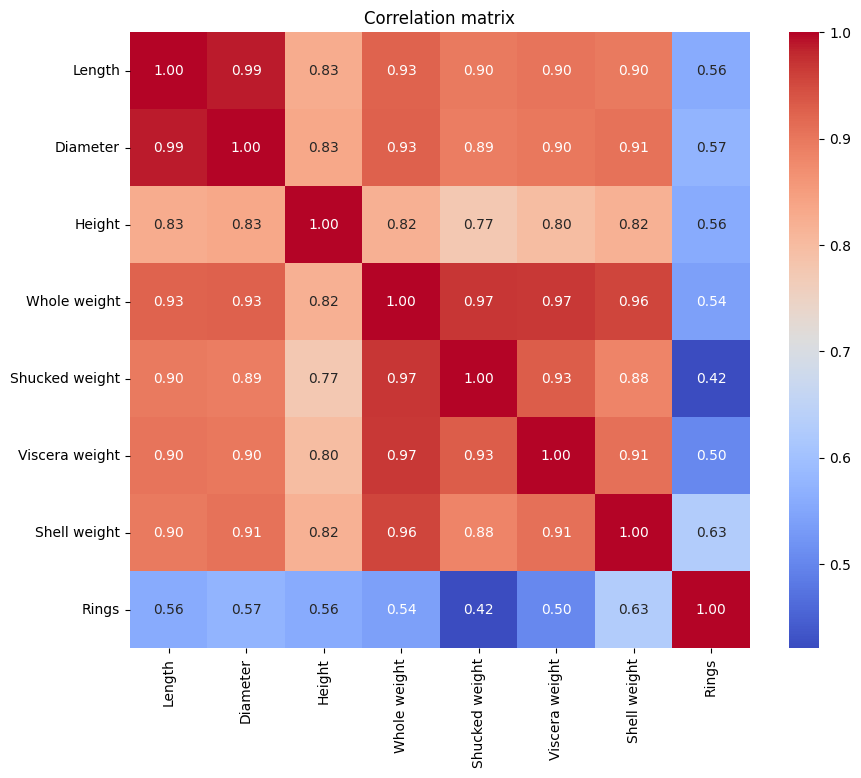

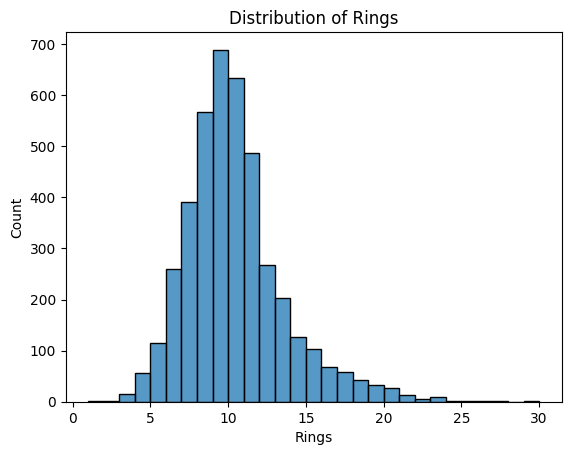

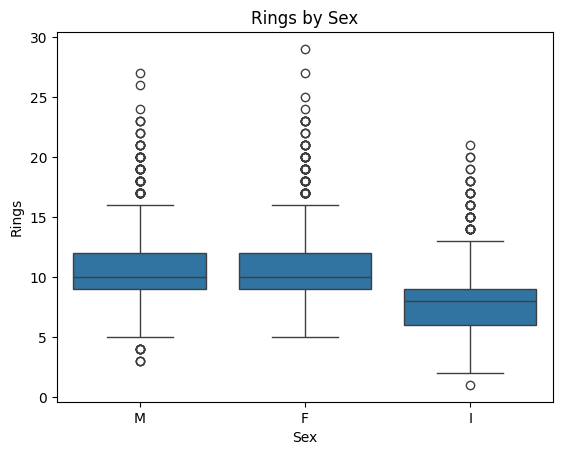

Rings             1.000000
Shell weight      0.627574
Diameter          0.574660
Height            0.557467
Length            0.556720
Whole weight      0.540390
Viscera weight    0.503819
Shucked weight    0.420884
Name: Rings, dtype: float64


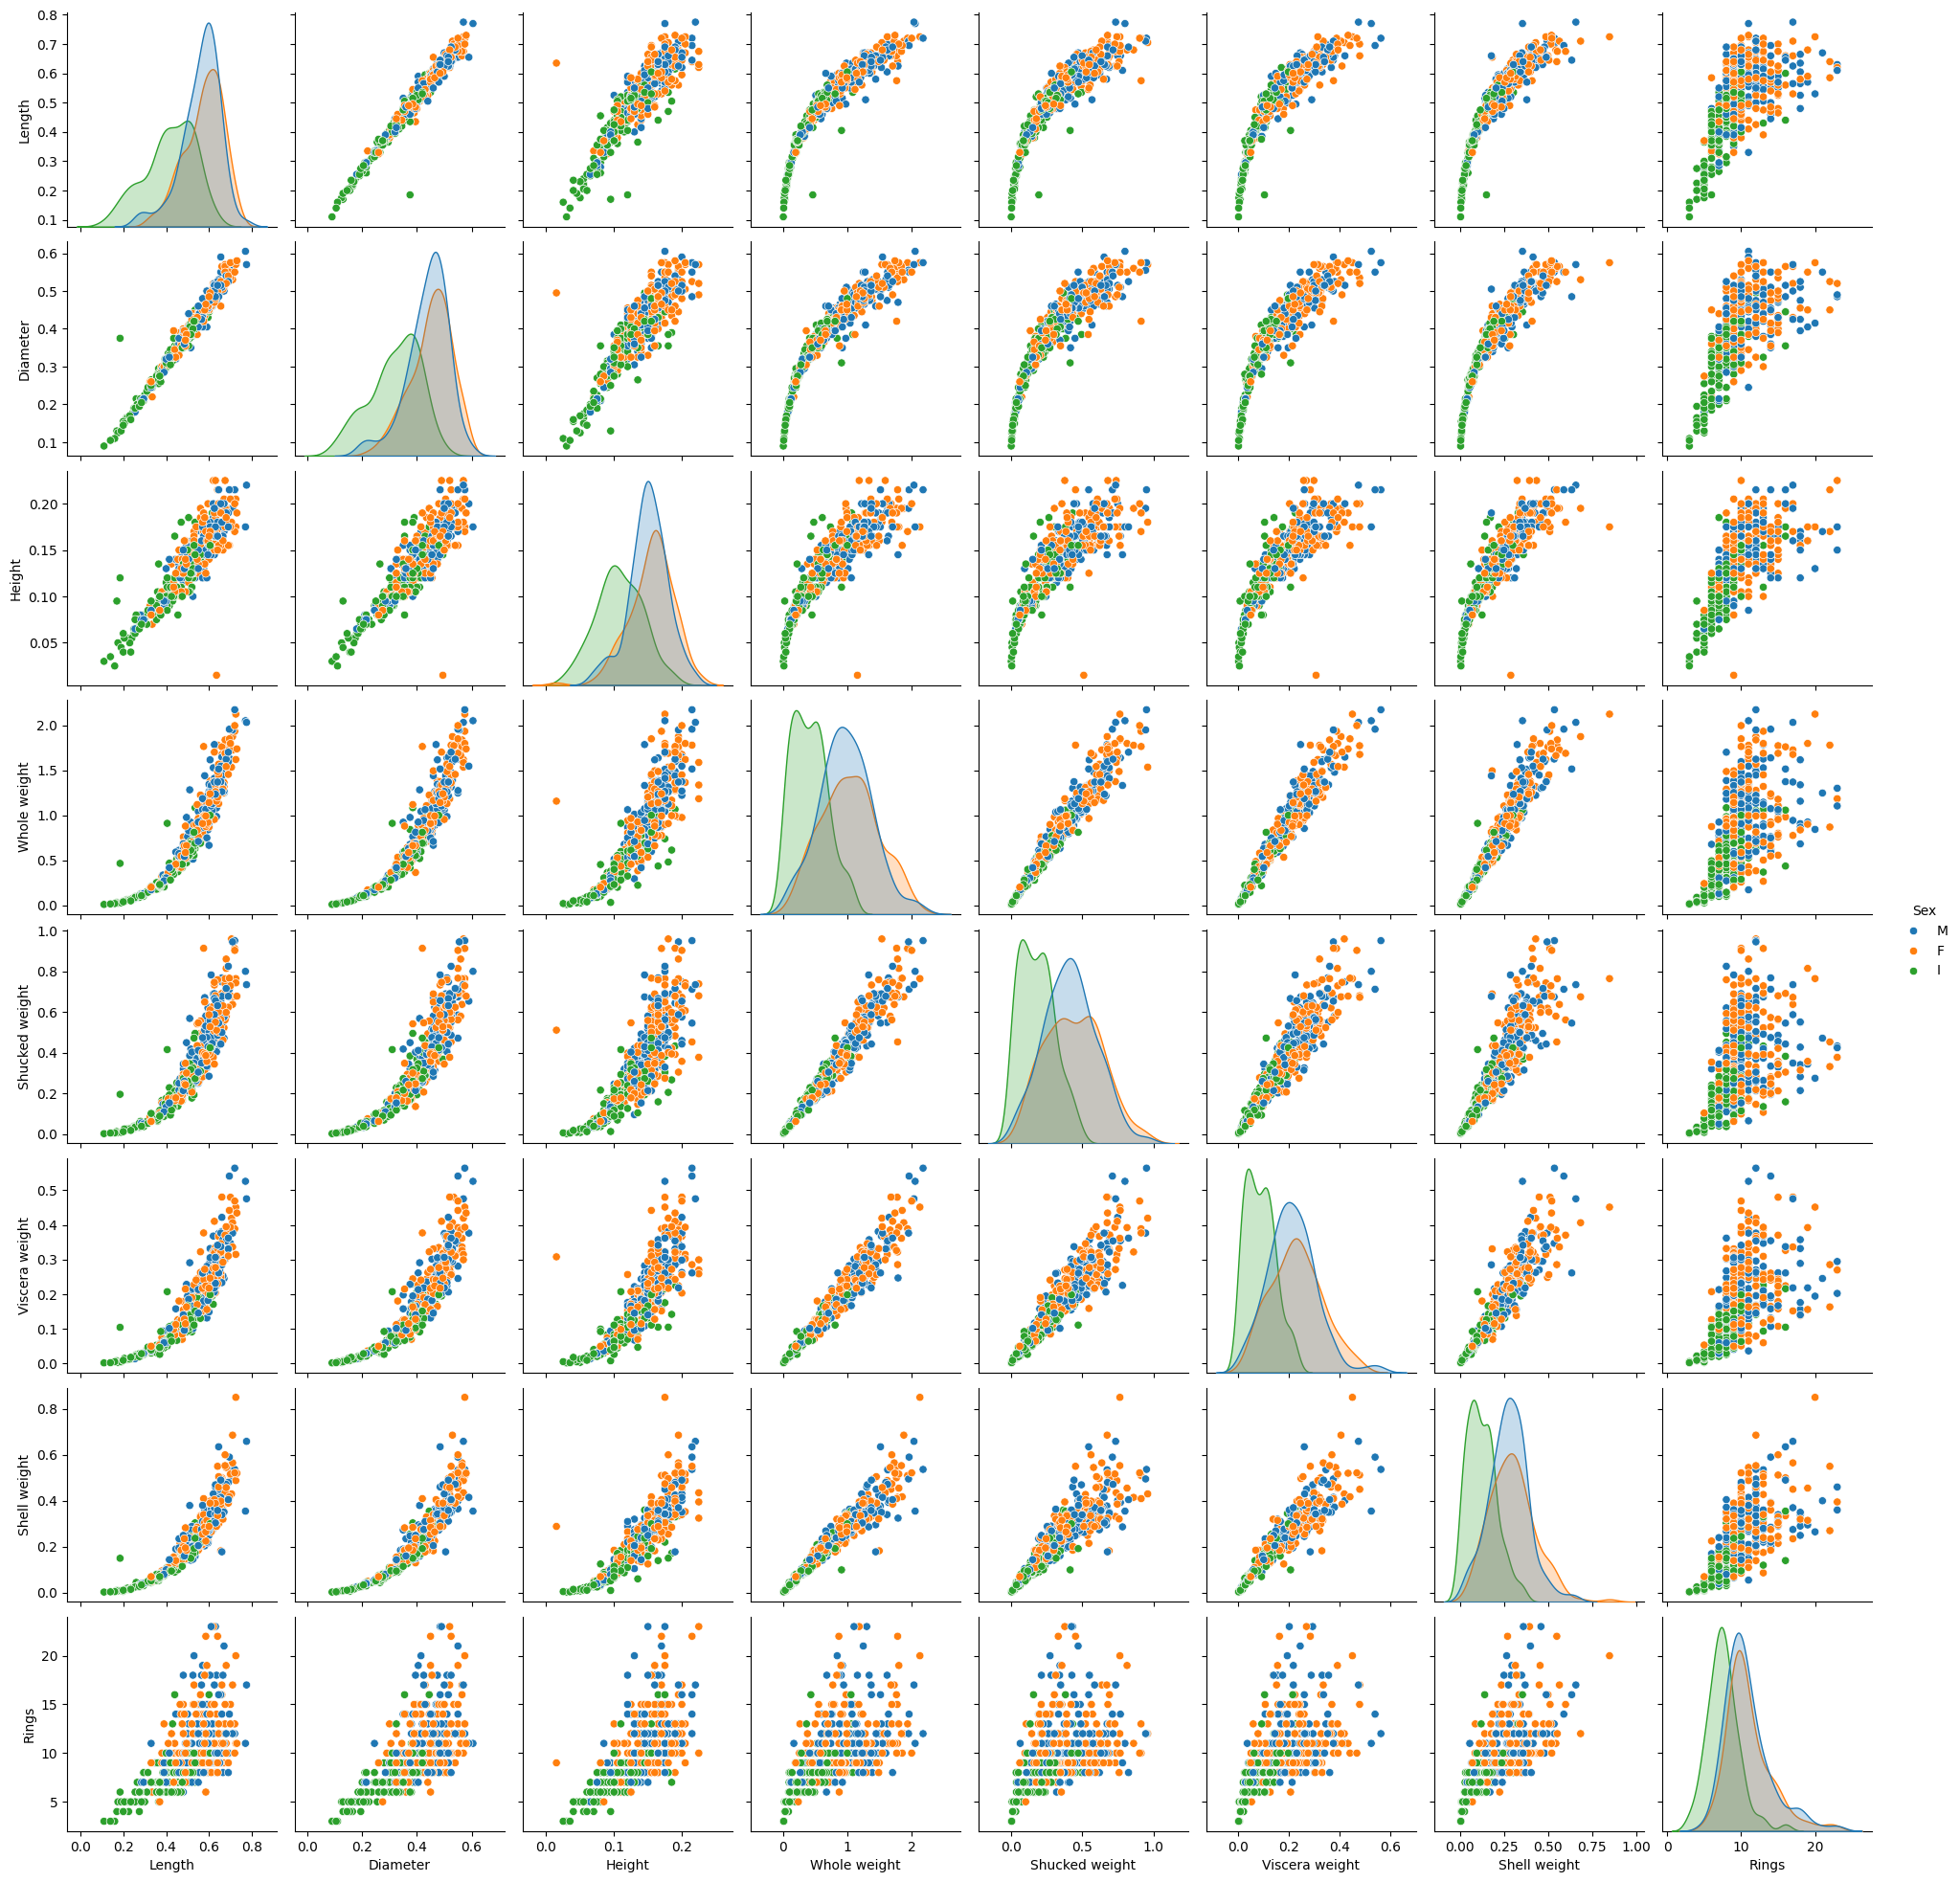

In [ ]:
print("Shape:", df.shape)
df.info()

# %% First rows
df.head()

# %% Summary statistics (numeric + categorical)
display(df.describe().T)
display(df.describe(include="object").T)

# %% Missing values and duplicates
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

# %% Categorical columns: counts
cat_cols = df.select_dtypes(include="object").columns
for col in cat_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())

# %% Numeric distributions
num_cols = df.select_dtypes(include="number").columns
df[num_cols].hist(bins=30, figsize=(14, 10))
plt.tight_layout()
plt.show()

# %% Outliers (boxplots)
fig, axes = plt.subplots(2, (len(num_cols) + 1) // 2, figsize=(16, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# %% Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()

# %% Target (Rings) vs features, split by categorical column
target = "Rings"  # change if your target column is named differently
if target in df.columns:
    sns.histplot(
        df[target], bins=range(int(df[target].min()), int(df[target].max()) + 2)
    )
    plt.title(f"Distribution of {target}")
    plt.show()

    for col in cat_cols:
        sns.boxplot(x=col, y=target, data=df)
        plt.title(f"{target} by {col}")
        plt.show()

    print(df[num_cols].corr()[target].sort_values(ascending=False))

# %% Pairplot of a few key features (can be slow on large data)
sns.pairplot(
    df.sample(min(len(df), 500), random_state=42),
    hue=cat_cols[0] if len(cat_cols) else None,
)
plt.show()